# Taller de modelado dimensional: Data Warehouse académico del ITM

**Estudiante:** Santiago Jaramillo Valencia
**Curso:** Tópicos Avanzados de Bases de Datos, Ingeniería en Ciencia de Datos, ITM

Se construye un prototipo de Data Warehouse con esquema en estrella sobre DuckDB a partir de datos de matrícula simulados (2022-1 a 2024-2), para calcular indicadores de rendimiento y permanencia.

## Fase 1. Datos operacionales sintéticos

Simulo la tabla plana que entregaría el sistema de matrículas: una fila por estudiante inscrito en una asignatura en un periodo. Para que los resultados tengan algo que contar, la nota no es puramente aleatoria: depende un poco de la dificultad del área, del estrato, de la jornada y de la capacidad de cada estudiante. Los estudiantes y las asignaturas tienen atributos fijos (el estrato de un estudiante no cambia entre filas). Las cancelaciones se registran con nota 0.0 y estado `Cancelada`, alrededor del 6,5% de las filas.

In [1]:
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
np.random.seed(2026)

N_EST = 4500
periodos = ["2022-1", "2022-2", "2023-1", "2023-2", "2024-1", "2024-2"]

# --- Catálogo de asignaturas (41) con su área y dificultad relativa ---
catalogo = {
    "Matemáticas": (-0.45, ["Cálculo Diferencial", "Cálculo Integral", "Álgebra Lineal", "Probabilidad",
                            "Estadística", "Matemáticas Discretas", "Ecuaciones Diferenciales", "Cálculo Multivariado"]),
    "Programación": (-0.15, ["Fundamentos de Programación", "Programación Orientada a Objetos", "Estructuras de Datos",
                             "Algoritmos", "Programación Web", "Desarrollo Móvil", "Arquitectura de Software",
                             "Pruebas de Software", "Inteligencia Artificial", "Machine Learning"]),
    "Bases de Datos": (-0.05, ["Bases de Datos I", "Bases de Datos II", "Modelado de Datos",
                               "Data Warehousing", "Bases de Datos NoSQL", "Minería de Datos"]),
    "Humanidades": (0.35, ["Ética Profesional", "Comunicación Oral y Escrita", "Constitución y Democracia",
                           "Inglés I", "Inglés II", "Inglés III", "Emprendimiento", "Cátedra ITM"]),
    "Electrónica y Redes": (-0.30, ["Física Mecánica", "Física Electromagnética", "Circuitos Eléctricos",
                                    "Electrónica Digital", "Electrónica Análoga", "Sistemas Embebidos",
                                    "Señales y Sistemas", "Redes de Computadores", "Sistemas Operativos"]),
}
filas = []
for area, (dif, nombres) in catalogo.items():
    for n in nombres:
        filas.append({"nombre_asignatura": n, "area_conocimiento": area, "dif": dif})
asig = pd.DataFrame(filas)
asig["id_asignatura"] = np.arange(101, 101 + len(asig))          # código de negocio (101..141)
asig["creditos"] = np.random.randint(2, 5, len(asig))            # 2 a 4 créditos

# --- Programas ---
prog = pd.DataFrame({
    "id_programa": [10, 20, 30, 40],
    "nombre_programa": ["Ingeniería en Ciencia de Datos", "Ingeniería de Sistemas",
                        "Tecnología en Desarrollo de Software", "Ingeniería Electrónica"],
    "facultad": ["Ciencias Exactas y Aplicadas", "Ingenierías", "Ingenierías", "Ingenierías"],
    "off_prog": [0.10, 0.00, -0.05, -0.10],
})

# --- Estudiantes: programa, estrato, jornada y capacidad (fijos por estudiante) ---
est = pd.DataFrame({
    "id_estudiante": np.arange(1, N_EST + 1),
    "id_programa": np.random.choice(prog["id_programa"], N_EST, p=[0.30, 0.30, 0.20, 0.20]),
    "estrato": np.random.choice([1, 2, 3, 4, 5], N_EST, p=[0.20, 0.30, 0.28, 0.14, 0.08]),
    "jornada": np.random.choice(["Diurna", "Nocturna"], N_EST, p=[0.65, 0.35]),
    "capacidad": np.random.normal(0, 0.40, N_EST),
})

# --- Matrículas: se muestrean combinaciones y se quitan repetidas (estudiante, asignatura, periodo) ---
n_cand = 65_000
cand = pd.DataFrame({
    "id_estudiante": np.random.randint(1, N_EST + 1, n_cand),
    "id_asignatura": np.random.choice(asig["id_asignatura"], n_cand),
    "periodo": np.random.choice(periodos, n_cand, p=[0.14, 0.15, 0.16, 0.17, 0.18, 0.20]),
})
cand = cand.drop_duplicates(["id_estudiante", "id_asignatura", "periodo"]).head(60_000).reset_index(drop=True)
cand.insert(0, "id_matricula", np.arange(1, len(cand) + 1))

m = (cand.merge(est, on="id_estudiante").merge(asig, on="id_asignatura").merge(prog, on="id_programa")
         .sort_values("id_matricula").reset_index(drop=True))

# --- Nota final ---
media = (3.75 + m["dif"] + m["off_prog"] + m["capacidad"]
         + 0.08 * (m["estrato"] - 3) - 0.12 * (m["jornada"] == "Nocturna"))
nota = np.round(np.clip(np.random.normal(media, 0.75), 0.1, 5.0), 1)
cancelada = np.random.rand(len(m)) < 0.065
m["nota_final"] = np.where(cancelada, 0.0, nota)
m["estado_asignatura"] = np.select([cancelada, m["nota_final"] >= 3.0], ["Cancelada", "Aprobada"], default="Reprobada")

matriculas = m[["id_matricula", "id_estudiante", "id_asignatura", "id_programa", "nombre_programa", "facultad",
                "periodo", "nombre_asignatura", "area_conocimiento", "creditos",
                "estrato", "jornada", "nota_final", "estado_asignatura"]]
print(matriculas.shape)
matriculas.head()

(60000, 14)


,id_matricula,id_estudiante,id_asignatura,id_programa,nombre_programa,facultad,periodo,nombre_asignatura,area_conocimiento,creditos,estrato,jornada,nota_final,estado_asignatura
0,1,1591,123,10,Ingeniería en Ciencia de Datos,Ciencias Exactas y Aplicadas,2024-1,Bases de Datos NoSQL,Bases de Datos,3,1,Diurna,2.8,Reprobada
1,2,23,122,30,Tecnología en Desarrollo de Software,Ingenierías,2023-1,Data Warehousing,Bases de Datos,4,3,Diurna,4.2,Aprobada
2,3,1834,140,10,Ingeniería en Ciencia de Datos,Ciencias Exactas y Aplicadas,2024-2,Redes de Computadores,Electrónica y Redes,2,3,Diurna,3.5,Aprobada
3,4,3977,116,30,Tecnología en Desarrollo de Software,Ingenierías,2023-2,Pruebas de Software,Programación,2,1,Nocturna,3.7,Aprobada
4,5,1068,131,20,Ingeniería de Sistemas,Ingenierías,2022-1,Emprendimiento,Humanidades,3,3,Diurna,4.3,Aprobada


In [2]:
# Chequeo de lo que pide la guía
print("Registros:", len(matriculas), "| estudiantes:", matriculas["id_estudiante"].nunique(),
      "| asignaturas:", matriculas["id_asignatura"].nunique(), "| programas:", matriculas["id_programa"].nunique())
print("Periodos:", sorted(matriculas["periodo"].unique()))
print()
print(matriculas["estado_asignatura"].value_counts(normalize=True).round(3))

Registros: 60000 | estudiantes: 4500 | asignaturas: 41 | programas: 4
Periodos: ['2022-1', '2022-2', '2023-1', '2023-2', '2024-1', '2024-2']

estado_asignatura
Aprobada     0.695
Reprobada    0.240
Cancelada    0.065
Name: proportion, dtype: float64


## Fase 2. Diseño del modelo

### Granularidad

**Una fila de `hechos_rendimiento_academico` representa la inscripción de un estudiante en una asignatura durante un periodo académico, con su resultado final.** Es el nivel atómico: un estudiante, una asignatura y un periodo identifican una sola fila (`id_matricula` queda como dimensión degenerada). Todo lo demás (por programa, por área, por semestre, por estrato) se obtiene agregando hacia arriba, y no se puede bajar a más detalle del que se declara aquí.

### Medidas (hechos)

| Medida | Tipo | Comentario |
|---|---|---|
| `creditos_matriculados` | Aditiva | Se puede sumar por cualquier dimensión, incluido el tiempo. |
| `creditos_aprobados` | Aditiva | Igual que la anterior. |
| `es_aprobada`, `es_reprobada`, `es_cancelada` | Aditivas | Al sumarlas dan conteos y al promediarlas dan tasas. |
| `nota_final` | No aditiva | Sumar notas no tiene sentido; solo se promedia (idealmente ponderada por créditos). |

Aquí no hay medidas semi-aditivas, que serían del tipo "saldo" o "créditos acumulados a la fecha": se pueden sumar entre estudiantes pero no a lo largo del tiempo. Aparecerían si se agregara un hecho de foto (*snapshot*) por periodo.

### Dimensiones y llaves sustitutas

Hay cuatro dimensiones (`dim_estudiante`, `dim_asignatura`, `dim_programa`, `dim_periodo`), cada una con una llave sustituta entera (`*_dw`) generada dentro del almacén y con la llave de negocio guardada como atributo (`*_origen`). Se usan sustitutas porque: (1) el almacén no depende de los códigos del sistema de matrículas, que pueden cambiar o reutilizarse; (2) permiten conservar historia si un atributo cambia (dimensión tipo 2); (3) los enteros pequeños ocupan menos y hacen los joins más rápidos que llaves de texto; (4) se pueden integrar varias fuentes sin choque de códigos.

```
dim_estudiante ─┐
dim_asignatura ─┼──> hechos_rendimiento_academico
dim_programa   ─┤
dim_periodo    ─┘
```

## Fase 3. Construcción del DW en DuckDB (ETL)

In [3]:
import os
if os.path.exists("dw_academico.duckdb"):
    os.remove("dw_academico.duckdb")

con = duckdb.connect("dw_academico.duckdb")
con.register("stg_matricula", matriculas);   # la fuente operacional queda como vista de staging

In [4]:
# DDL de las dimensiones
con.execute("""
CREATE TABLE dim_estudiante (
    id_estudiante_dw     INTEGER PRIMARY KEY,
    id_estudiante_origen INTEGER NOT NULL UNIQUE,
    estrato              TINYINT NOT NULL CHECK (estrato BETWEEN 1 AND 5),
    jornada              VARCHAR NOT NULL
)""")

con.execute("""
CREATE TABLE dim_asignatura (
    id_asignatura_dw     INTEGER PRIMARY KEY,
    id_asignatura_origen INTEGER NOT NULL UNIQUE,
    nombre_asignatura    VARCHAR NOT NULL,
    area_conocimiento    VARCHAR NOT NULL,
    creditos             TINYINT NOT NULL CHECK (creditos BETWEEN 2 AND 4)
)""")

con.execute("""
CREATE TABLE dim_programa (
    id_programa_dw     INTEGER PRIMARY KEY,
    id_programa_origen INTEGER NOT NULL UNIQUE,
    nombre_programa    VARCHAR NOT NULL,
    facultad           VARCHAR NOT NULL
)""")

con.execute("""
CREATE TABLE dim_periodo (
    id_periodo_dw  INTEGER PRIMARY KEY,
    codigo_periodo VARCHAR NOT NULL UNIQUE,
    "año"          SMALLINT NOT NULL,
    semestre       TINYINT NOT NULL CHECK (semestre IN (1, 2))
)""")

# DDL de la tabla de hechos
con.execute("""
CREATE TABLE hechos_rendimiento_academico (
    id_matricula          INTEGER PRIMARY KEY,                -- dimensión degenerada
    id_estudiante_dw      INTEGER NOT NULL REFERENCES dim_estudiante(id_estudiante_dw),
    id_asignatura_dw      INTEGER NOT NULL REFERENCES dim_asignatura(id_asignatura_dw),
    id_programa_dw        INTEGER NOT NULL REFERENCES dim_programa(id_programa_dw),
    id_periodo_dw         INTEGER NOT NULL REFERENCES dim_periodo(id_periodo_dw),
    nota_final            DECIMAL(3,1) NOT NULL CHECK (nota_final BETWEEN 0 AND 5),
    creditos_matriculados TINYINT NOT NULL,
    creditos_aprobados    TINYINT NOT NULL,
    es_aprobada           TINYINT NOT NULL CHECK (es_aprobada  IN (0, 1)),
    es_reprobada          TINYINT NOT NULL CHECK (es_reprobada IN (0, 1)),
    es_cancelada          TINYINT NOT NULL CHECK (es_cancelada IN (0, 1)),
    CHECK (es_aprobada + es_reprobada + es_cancelada = 1)     -- los tres estados son excluyentes
)""")
print("Estructuras creadas")

Estructuras creadas


In [5]:
# Carga de dimensiones: llave sustituta con ROW_NUMBER sobre los valores únicos de la fuente
con.execute("""
INSERT INTO dim_estudiante
SELECT ROW_NUMBER() OVER (ORDER BY id_estudiante), id_estudiante, estrato, jornada
FROM (SELECT DISTINCT id_estudiante, estrato, jornada FROM stg_matricula)""")

con.execute("""
INSERT INTO dim_asignatura
SELECT ROW_NUMBER() OVER (ORDER BY id_asignatura), id_asignatura, nombre_asignatura, area_conocimiento, creditos
FROM (SELECT DISTINCT id_asignatura, nombre_asignatura, area_conocimiento, creditos FROM stg_matricula)""")

con.execute("""
INSERT INTO dim_programa
SELECT ROW_NUMBER() OVER (ORDER BY id_programa), id_programa, nombre_programa, facultad
FROM (SELECT DISTINCT id_programa, nombre_programa, facultad FROM stg_matricula)""")

con.execute("""
INSERT INTO dim_periodo
SELECT ROW_NUMBER() OVER (ORDER BY periodo),
       periodo,
       CAST(SUBSTR(periodo, 1, 4) AS SMALLINT),
       CAST(SUBSTR(periodo, 6, 1) AS TINYINT)
FROM (SELECT DISTINCT periodo FROM stg_matricula)""")

# Carga de hechos: se traducen las llaves de negocio a sustitutas y se calculan las medidas
con.execute("""
INSERT INTO hechos_rendimiento_academico
SELECT
    m.id_matricula,
    e.id_estudiante_dw,
    a.id_asignatura_dw,
    p.id_programa_dw,
    pe.id_periodo_dw,
    m.nota_final,
    m.creditos                                                       AS creditos_matriculados,
    CASE WHEN m.estado_asignatura = 'Aprobada'  THEN m.creditos ELSE 0 END AS creditos_aprobados,
    CASE WHEN m.estado_asignatura = 'Aprobada'  THEN 1 ELSE 0 END    AS es_aprobada,
    CASE WHEN m.estado_asignatura = 'Reprobada' THEN 1 ELSE 0 END    AS es_reprobada,
    CASE WHEN m.estado_asignatura = 'Cancelada' THEN 1 ELSE 0 END    AS es_cancelada
FROM stg_matricula m
JOIN dim_estudiante  e  ON e.id_estudiante_origen = m.id_estudiante
JOIN dim_asignatura  a  ON a.id_asignatura_origen = m.id_asignatura
JOIN dim_programa    p  ON p.id_programa_origen   = m.id_programa
JOIN dim_periodo     pe ON pe.codigo_periodo      = m.periodo""")

for t in ["dim_estudiante", "dim_asignatura", "dim_programa", "dim_periodo", "hechos_rendimiento_academico"]:
    print(f"{t:30s} {con.execute(f'SELECT COUNT(*) FROM {t}').fetchone()[0]:>8,} filas")

dim_estudiante                    4,500 filas
dim_asignatura                       41 filas
dim_programa                          4 filas
dim_periodo                           6 filas
hechos_rendimiento_academico     60,000 filas


In [6]:
con.execute("SELECT * FROM hechos_rendimiento_academico LIMIT 5").df()

,id_matricula,id_estudiante_dw,id_asignatura_dw,id_programa_dw,id_periodo_dw,nota_final,creditos_matriculados,creditos_aprobados,es_aprobada,es_reprobada,es_cancelada
0,1,1591,23,1,5,2.8,3,0,0,1,0
1,2,23,22,3,3,4.2,4,4,1,0,0
2,3,1834,40,1,6,3.5,2,2,1,0,0
3,4,3977,16,3,4,3.7,2,2,1,0,0
4,5,1068,31,2,1,4.3,3,3,1,0,0


### Validación de integridad del ETL

In [7]:
def uno(sql):
    return con.execute(sql).fetchone()[0]

n_fuente = len(matriculas)
n_hechos = uno("SELECT COUNT(*) FROM hechos_rendimiento_academico")

chequeos = [
    ("Filas fuente = filas en hechos",            n_fuente, n_hechos),
    ("id_matricula duplicados en hechos",         0, n_hechos - uno("SELECT COUNT(DISTINCT id_matricula) FROM hechos_rendimiento_academico")),
    ("Hechos huérfanos (estudiante)",             0, uno("SELECT COUNT(*) FROM hechos_rendimiento_academico f LEFT JOIN dim_estudiante d USING (id_estudiante_dw) WHERE d.id_estudiante_dw IS NULL")),
    ("Hechos huérfanos (asignatura)",             0, uno("SELECT COUNT(*) FROM hechos_rendimiento_academico f LEFT JOIN dim_asignatura d USING (id_asignatura_dw) WHERE d.id_asignatura_dw IS NULL")),
    ("Hechos huérfanos (programa)",               0, uno("SELECT COUNT(*) FROM hechos_rendimiento_academico f LEFT JOIN dim_programa d USING (id_programa_dw) WHERE d.id_programa_dw IS NULL")),
    ("Hechos huérfanos (periodo)",                0, uno("SELECT COUNT(*) FROM hechos_rendimiento_academico f LEFT JOIN dim_periodo d USING (id_periodo_dw) WHERE d.id_periodo_dw IS NULL")),
    ("Créditos matriculados: fuente = hechos",    int(matriculas["creditos"].sum()), uno("SELECT SUM(creditos_matriculados) FROM hechos_rendimiento_academico")),
    ("Aprobadas: fuente = hechos",                int((matriculas["estado_asignatura"] == "Aprobada").sum()), uno("SELECT SUM(es_aprobada) FROM hechos_rendimiento_academico")),
]
val = pd.DataFrame(chequeos, columns=["Chequeo", "Esperado", "Obtenido"])
val["Resultado"] = np.where(val["Esperado"] == val["Obtenido"], "OK", "FALLA")
display(val)
assert (val["Resultado"] == "OK").all(), "El ETL no pasó la validación"
print("ETL validado: sin duplicados ni huérfanos.")

,Chequeo,Esperado,Obtenido,Resultado
0,Filas fuente = filas en hechos,60000,60000,OK
1,id_matricula duplicados en hechos,0,0,OK
2,Hechos huérfanos (estudiante),0,0,OK
3,Hechos huérfanos (asignatura),0,0,OK
4,Hechos huérfanos (programa),0,0,OK
5,Hechos huérfanos (periodo),0,0,OK
6,Créditos matriculados: fuente = hechos,166467,166467,OK
7,Aprobadas: fuente = hechos,41690,41690,OK


ETL validado: sin duplicados ni huérfanos.


## Fase 4. Consultas analíticas (SQL OLAP)

Convenciones que usé en todas las consultas: la **tasa de aprobación** es `SUM(es_aprobada) / COUNT(*)`, con las canceladas dentro del denominador (son inscripciones que no terminaron en aprobación). La **nota promedio** excluye las canceladas, porque su 0.0 no es una calificación real y sesgaría el promedio hacia abajo.

**Consulta 1. Rendimiento por programa y periodo**

In [8]:
q1 = """
SELECT
    p.nombre_programa,
    pe.codigo_periodo                                              AS periodo,
    COUNT(*)                                                       AS inscripciones,
    ROUND(AVG(f.nota_final) FILTER (WHERE f.es_cancelada = 0), 2)  AS nota_promedio,
    ROUND(100.0 * SUM(f.es_aprobada) / COUNT(*), 2)                AS tasa_aprobacion_pct
FROM hechos_rendimiento_academico f
JOIN dim_programa p  ON p.id_programa_dw  = f.id_programa_dw
JOIN dim_periodo  pe ON pe.id_periodo_dw  = f.id_periodo_dw
GROUP BY p.nombre_programa, pe.codigo_periodo
ORDER BY p.nombre_programa, pe.codigo_periodo
"""
r1 = con.execute(q1).df()
r1

,nombre_programa,periodo,inscripciones,nota_promedio,tasa_aprobacion_pct
0,Ingeniería Electrónica,2022-1,1827,3.42,65.24
1,Ingeniería Electrónica,2022-2,1912,3.43,67.00
2,Ingeniería Electrónica,2023-1,2006,3.43,66.95
3,Ingeniería Electrónica,2023-2,2214,3.43,65.72
4,Ingeniería Electrónica,2024-1,2314,3.45,66.21
5,Ingeniería Electrónica,2024-2,2480,3.44,66.53
6,Ingeniería de Sistemas,2022-1,2406,3.53,68.91
7,Ingeniería de Sistemas,2022-2,2664,3.52,69.18
8,Ingeniería de Sistemas,2023-1,2794,3.52,68.47
9,Ingeniería de Sistemas,2023-2,2936,3.53,70.13


**Consulta 2. Las 5 asignaturas con más reprobaciones en 2024**

In [9]:
q2 = """
SELECT
    a.nombre_asignatura,
    a.area_conocimiento,
    COUNT(DISTINCT f.id_estudiante_dw)               AS estudiantes_que_la_cursaron,
    CAST(SUM(f.es_reprobada) AS INTEGER)             AS reprobaciones,
    ROUND(100.0 * SUM(f.es_reprobada) / COUNT(*), 2) AS pct_reprobacion
FROM hechos_rendimiento_academico f
JOIN dim_asignatura a  ON a.id_asignatura_dw = f.id_asignatura_dw
JOIN dim_periodo    pe ON pe.id_periodo_dw   = f.id_periodo_dw
WHERE pe."año" = 2024
GROUP BY a.nombre_asignatura, a.area_conocimiento
ORDER BY reprobaciones DESC
LIMIT 5
"""
con.execute(q2).df()

,nombre_asignatura,area_conocimiento,estudiantes_que_la_cursaron,reprobaciones,pct_reprobacion
0,Ecuaciones Diferenciales,Matemáticas,552,199,35.10
1,Cálculo Multivariado,Matemáticas,523,197,36.89
2,Probabilidad,Matemáticas,540,194,34.95
3,Cálculo Integral,Matemáticas,547,194,34.15
4,Álgebra Lineal,Matemáticas,532,187,34.63


**Consulta 3. Aprobación y créditos aprobados por semestre, estrato y jornada**

In [10]:
q3 = """
SELECT
    pe.codigo_periodo                                  AS periodo,
    e.estrato,
    e.jornada,
    COUNT(*)                                           AS inscripciones,
    ROUND(100.0 * SUM(f.es_aprobada) / COUNT(*), 2)    AS tasa_aprobacion_pct,
    ROUND(AVG(f.creditos_aprobados), 2)                AS prom_creditos_aprobados
FROM hechos_rendimiento_academico f
JOIN dim_estudiante e  ON e.id_estudiante_dw = f.id_estudiante_dw
JOIN dim_periodo    pe ON pe.id_periodo_dw   = f.id_periodo_dw
GROUP BY pe.codigo_periodo, e.estrato, e.jornada
ORDER BY pe.codigo_periodo, e.estrato, e.jornada
"""
r3 = con.execute(q3).df()
print(f"{len(r3)} combinaciones periodo-estrato-jornada. Primeras filas:")
display(r3.head(10))

# Vista resumida para leerla más fácil: tasa de aprobación promedio por estrato y jornada
(r3.assign(aprob=r3["tasa_aprobacion_pct"] * r3["inscripciones"])
   .groupby(["estrato", "jornada"]).apply(lambda g: g["aprob"].sum() / g["inscripciones"].sum(), include_groups=False)
   .round(2).unstack().rename_axis(columns=None).rename(columns=lambda c: f"Tasa aprob. % ({c})"))

60 combinaciones periodo-estrato-jornada. Primeras filas:


,periodo,estrato,jornada,inscripciones,tasa_aprobacion_pct,prom_creditos_aprobados
0,2022-1,1,Diurna,1047,66.95,1.83
1,2022-1,1,Nocturna,691,62.52,1.73
2,2022-1,2,Diurna,1704,68.37,1.90
3,2022-1,2,Nocturna,860,66.98,1.82
4,2022-1,3,Diurna,1508,71.55,1.98
5,2022-1,3,Nocturna,803,67.87,1.86
6,2022-1,4,Diurna,800,76.38,2.11
7,2022-1,4,Nocturna,409,68.22,1.91
8,2022-1,5,Diurna,416,73.32,2.01
9,2022-1,5,Nocturna,215,67.91,1.93


,Tasa aprob. % (Diurna),Tasa aprob. % (Nocturna)
estrato,,
1,66.18,62.77
2,70.36,64.64
3,71.47,68.52
4,75.40,68.96
5,77.90,71.96


**Consulta 4. Eficiencia de créditos por programa**

In [11]:
q4 = """
SELECT
    p.nombre_programa,
    CAST(SUM(f.creditos_matriculados) AS INTEGER)                      AS creditos_matriculados,
    CAST(SUM(f.creditos_aprobados) AS INTEGER)                         AS creditos_aprobados,
    ROUND(SUM(f.creditos_aprobados) * 1.0 / SUM(f.creditos_matriculados), 4) AS eficiencia_academica
FROM hechos_rendimiento_academico f
JOIN dim_programa p ON p.id_programa_dw = f.id_programa_dw
GROUP BY p.nombre_programa
ORDER BY eficiencia_academica DESC
"""
con.execute(q4).df()

,nombre_programa,creditos_matriculados,creditos_aprobados,eficiencia_academica
0,Ingeniería en Ciencia de Datos,49670,36216,0.7291
1,Ingeniería de Sistemas,47656,32814,0.6886
2,Tecnología en Desarrollo de Software,33674,22624,0.6719
3,Ingeniería Electrónica,35467,23343,0.6582


**Consulta adicional. Riesgo por área de conocimiento** (para el informe)

In [12]:
q5 = """
SELECT
    a.area_conocimiento,
    COUNT(*)                                            AS inscripciones,
    ROUND(100.0 * SUM(f.es_reprobada) / COUNT(*), 2)    AS pct_reprobacion,
    ROUND(100.0 * SUM(f.es_cancelada) / COUNT(*), 2)    AS pct_cancelacion,
    ROUND(100.0 * SUM(f.es_aprobada)  / COUNT(*), 2)    AS pct_aprobacion
FROM hechos_rendimiento_academico f
JOIN dim_asignatura a ON a.id_asignatura_dw = f.id_asignatura_dw
GROUP BY a.area_conocimiento
ORDER BY pct_reprobacion DESC
"""
r5 = con.execute(q5).df()
r5

,area_conocimiento,inscripciones,pct_reprobacion,pct_cancelacion,pct_aprobacion
0,Matemáticas,11609,35.41,6.18,58.41
1,Electrónica y Redes,13080,29.75,6.62,63.63
2,Programación,14634,23.51,6.79,69.70
3,Bases de Datos,8770,20.38,6.44,73.18
4,Humanidades,11907,9.99,6.29,83.72


## Fase 5. Visualización e interpretación

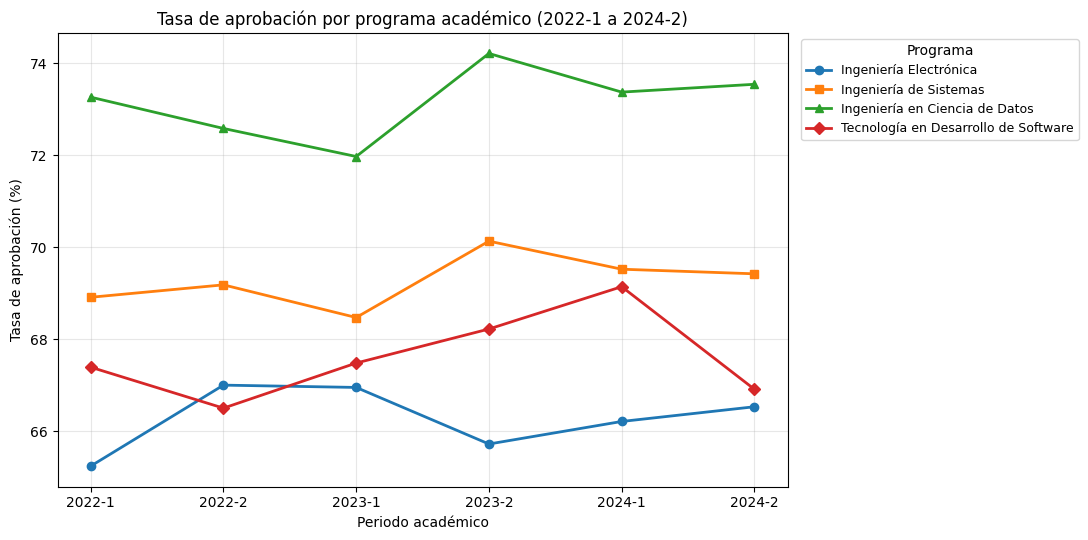

In [13]:
pivot = r1.pivot(index="periodo", columns="nombre_programa", values="tasa_aprobacion_pct")

fig, ax = plt.subplots(figsize=(11, 5.5))
for col, marcador in zip(pivot.columns, ["o", "s", "^", "D"]):
    ax.plot(pivot.index, pivot[col], marker=marcador, linewidth=2, label=col)
ax.set_title("Tasa de aprobación por programa académico (2022-1 a 2024-2)")
ax.set_xlabel("Periodo académico")
ax.set_ylabel("Tasa de aprobación (%)")
ax.grid(alpha=0.3)
ax.legend(title="Programa", loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.tight_layout()
plt.show()

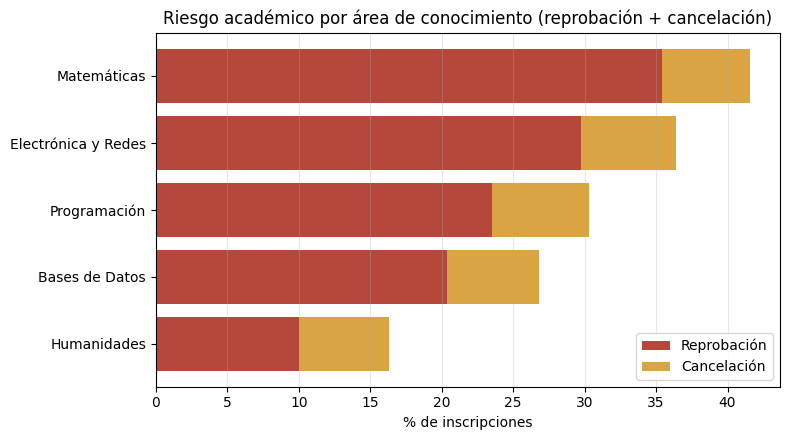

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
orden = r5.sort_values("pct_reprobacion")
ax.barh(orden["area_conocimiento"], orden["pct_reprobacion"], color="#b5483a", label="Reprobación")
ax.barh(orden["area_conocimiento"], orden["pct_cancelacion"], left=orden["pct_reprobacion"], color="#d9a441", label="Cancelación")
ax.set_xlabel("% de inscripciones")
ax.set_title("Riesgo académico por área de conocimiento (reprobación + cancelación)")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Informe de permanencia institucional

Un aviso antes de interpretar: los datos son sintéticos, así que estos patrones reflejan los parámetros que usé al simularlos. Con datos reales habría que validarlos, pero el método y las consultas son los mismos.

**¿Qué áreas concentran el mayor riesgo académico?**
Matemáticas es la más crítica: reprueba el 35,4% de sus inscripciones, y las cinco asignaturas con más reprobaciones en 2024 son todas de esa área (Ecuaciones Diferenciales, Cálculo Multivariado, Probabilidad, Cálculo Integral y Álgebra Lineal, con 34% a 37% de reprobación). Le sigue Electrónica y Redes con 29,8%. En el otro extremo, Humanidades reprueba solo el 10%. La cancelación es casi igual en todas las áreas (alrededor de 6% a 7%), así que lo que distingue el riesgo es la reprobación. Por estrato y jornada se ven brechas: la tasa de aprobación va de 66% en estrato 1 diurno a 78% en estrato 5 diurno, y la jornada nocturna queda entre 3 y 6 puntos por debajo en todos los estratos. Por programa, Ciencia de Datos tiene la mejor eficiencia de créditos (0,73) y Electrónica la menor (0,66), con tasas estables a lo largo de los seis periodos. La Dirección podría priorizar tutorías en el ciclo básico de Matemáticas y acompañamiento a estudiantes de estratos bajos y de jornada nocturna.

**¿Por qué el modelo dimensional facilitó estos indicadores?**
Porque las preguntas se volvieron siempre el mismo patrón: unir el hecho con las dimensiones que se necesitan y agrupar. En la tabla plana el nombre del programa, el área o el estrato se repiten en cada una de las 60.000 filas, y cada indicador exigía reescribir la lógica de aprobación (comparando textos, tratando las canceladas). En la estrella esa lógica se calcula una sola vez en el ETL (`es_aprobada`, `creditos_aprobados`) y todas las consultas la reutilizan, así que dos analistas no pueden terminar con tasas distintas. Además las dimensiones son pequeñas (41 asignaturas, 4 programas, 6 periodos), los joins son baratos, y agregar una dimensión nueva o un atributo no obliga a tocar la tabla de hechos.

**¿Cómo conectarlo a un modelo predictivo de deserción?**
El DW puede alimentar una tabla de características por estudiante y periodo: promedio acumulado, proporción de reprobadas y canceladas, eficiencia de créditos, cambios entre periodos, más estrato, jornada y programa de las dimensiones. La variable objetivo se define con el mismo hecho: el estudiante deserta si no vuelve a tener matrícula en el periodo siguiente. Se leería con SQL desde DuckDB a pandas para entrenar con scikit-learn o similar, dividiendo por tiempo (entrenar con periodos pasados y probar en el último) para evitar fuga de información. Las predicciones volverían al DW como un nuevo hecho (por estudiante y periodo) para armar tableros de alertas tempranas para Bienestar.

## Preguntas

**1. Si el sistema de matrículas cambia el código de una asignatura por una reforma curricular, ¿cómo protegen las llaves sustitutas la integridad histórica?**

Los hechos no apuntan al código de negocio sino a `id_asignatura_dw`, que no cambia. El código viejo queda como un atributo más (`id_asignatura_origen`) de esa fila de la dimensión. Si hay reforma, se puede tratar como una dimensión de cambio lento tipo 2: se agrega una fila nueva con el código nuevo (y fechas de vigencia) y las matrículas anteriores siguen enlazadas a la fila vieja, mientras que las nuevas usan la nueva. Así los reportes históricos no se alteran, y si el código viejo se reutiliza para otra materia no se mezclan dos asignaturas distintas en una misma llave.

**2. ¿Por qué guardar indicadores binarios (1 y 0) en vez de consultar el texto 'Aprobada' con `WHERE`?**

Porque con 1 y 0 las medidas son aditivas: `SUM(es_aprobada)` da el conteo de aprobadas y `AVG(es_aprobada)` da la tasa directamente, sin repetir `CASE WHEN` ni filtros en cada consulta. Además, la regla de qué es "aprobada" (nota ≥ 3.0 y no cancelada) se define una sola vez en el ETL y no cada analista por su cuenta, se evitan errores por escribir mal el texto o diferencias de mayúsculas, y los números enteros pequeños ocupan menos y se comparan más rápido que las cadenas, algo que se nota en un motor columnar. En el modelo, además, los tres indicadores son excluyentes y hay un `CHECK` que lo garantiza.

**3. Si cada fila fuera el promedio acumulado semestral de un estudiante, ¿qué se ganaría y qué se perdería?**

Se ganaría rendimiento y simplicidad: habría muchas menos filas (una por estudiante y periodo, en vez de una por cada asignatura que cursa; en un semestre real son 5 a 7 asignaturas), por lo que las consultas de trayectoria, como el seguimiento del promedio o las alertas por estudiante, serían más rápidas y de más fácil lectura. Se perdería de forma irrecuperable el detalle por asignatura: no se podría saber qué materias reprueban más, ni el riesgo por área, ni el efecto de cada asignatura o de sus créditos, porque desde un promedio no se puede reconstruir lo que lo originó. Además, promediar promedios es incorrecto si no se pondera por créditos. Por eso lo recomendable es mantener la granularidad atómica y, si hace falta, construir encima una tabla agregada (o vista materializada) con ese nivel.

**4. ¿Por qué es preferible entrenar el modelo de deserción desde este DW y no desde la base transaccional?**

Porque el DW ya trae los datos limpios, validados y con definiciones únicas (qué es aprobar, qué es cancelar), y conserva la historia por periodo, que es indispensable para construir etiquetas y características sin mezclar el futuro con el pasado. Las dimensiones entregan las variables categóricas ya organizadas, no hay que cruzar tablas operacionales con estructuras cambiantes, y las consultas pesadas de entrenamiento no compiten con la operación de matrículas (bloqueos y latencia). También da reproducibilidad: el mismo cálculo se puede repetir cada semestre y la variable objetivo y las características quedan versionadas, lo que facilita auditar el modelo.